# Klasifikasi Kesegaran Buah

**Anggota kelompok**
- Carlos Leonardo J. Dongoran
- Joni Fernando
- Matthew Rivandi
- Percaya Mendrova
- Yohanes Cornelius Willfredi Simanjuntak

Rincian pembagian kerja ada di `docs/pembagian_tugas.md`.

## Pembagian tugas

| Anggota | Tugas sementara |
|---|---|
| Carlos Leonardo J. Dongoran | Sementara mengerjakan persiapan dan eksplorasi awal notebook (bagian 1–5). |
| Joni Fernando | Belum ditentukan; pembagian tugas menyusul. |
| Matthew Rivandi | Belum ditentukan; pembagian tugas menyusul. |
| Percaya Mendrova | Belum ditentukan; pembagian tugas menyusul. |
| Yohanes Cornelius Willfredi Simanjuntak | Belum ditentukan; pembagian tugas menyusul. |

Pembagian tugas anggota lainnya akan ditetapkan kemudian. Rincian status sementara ada di `docs/pembagian_tugas.md`.

## 1. Import library, seed, versi TensorFlow, GPU, dan konfigurasi

Seed digunakan agar pemilihan contoh gambar dan eksperimen lebih mudah diulang. Sel setup menampilkan versi TensorFlow dan GPU yang tersedia; TensorFlow bersifat opsional untuk tahap eksplorasi dataset. Ubah konfigurasi sesuai kebutuhan.

In [1]:
from pathlib import Path
import math
import random
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError

try:
    import tensorflow as tf
except ModuleNotFoundError as error:
    if error.name != "tensorflow":
        raise
    tf = None

BENIH_ACAK = 42
UKURAN_GAMBAR = (224, 224)
UKURAN_BATCH = 32
JUMLAH_EPOCH = 20
LAJU_BELAJAR = 1e-4
CONTOH_PER_KELAS = 1

random.seed(BENIH_ACAK)
np.random.seed(BENIH_ACAK)
if tf is not None:
    tf.random.set_seed(BENIH_ACAK)

FOLDER_PROYEK = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FOLDER_DATA_ASLI = FOLDER_PROYEK / "data" / "raw"
FOLDER_DATA_OLAHAN = FOLDER_PROYEK / "data" / "processed"
FOLDER_DATASET = FOLDER_DATA_OLAHAN / "Fruits Dataset"
FOLDER_MODEL = FOLDER_PROYEK / "models"
FOLDER_GAMBAR_HASIL = FOLDER_PROYEK / "results" / "figures"
LOKASI_ARSIP_DATA = FOLDER_DATA_ASLI / "Fruits Dataset.zip"

for folder_hasil in (FOLDER_DATA_OLAHAN, FOLDER_MODEL, FOLDER_GAMBAR_HASIL):
    folder_hasil.mkdir(parents=True, exist_ok=True)

def simpan_gambar_jika_belum_ada(fig, nama_file):
    lokasi_gambar = FOLDER_GAMBAR_HASIL / nama_file
    if lokasi_gambar.is_file():
        print(f"Grafik sudah ada, tidak ditimpa: {lokasi_gambar}")
        return
    fig.savefig(lokasi_gambar, dpi=150, bbox_inches="tight")
    print(f"Grafik disimpan: {lokasi_gambar}")

print(f"Benih acak: {BENIH_ACAK}")
if tf is None:
    print("TensorFlow belum terpasang; pemeriksaan versi dan GPU dilewati.")
else:
    print(f"Versi TensorFlow: {tf.__version__}")
    daftar_gpu = tf.config.list_physical_devices("GPU")
    print(f"GPU terdeteksi: {len(daftar_gpu)}")
    for gpu in daftar_gpu:
        print(f"- {gpu.name}")
print(f"Ukuran gambar: {UKURAN_GAMBAR}")
print(f"Ukuran batch: {UKURAN_BATCH} | Epoch: {JUMLAH_EPOCH} | Laju belajar: {LAJU_BELAJAR}")
print(f"Arsip dataset: {LOKASI_ARSIP_DATA}")

Benih acak: 42
TensorFlow belum terpasang; pemeriksaan versi dan GPU dilewati.
Ukuran gambar: (224, 224)
Ukuran batch: 32 | Epoch: 20 | Laju belajar: 0.0001
Arsip dataset: d:\231111859\latihan python\nyawit_Proyek1\data\raw\Fruits Dataset.zip


## 2. Ekstrak dan muat dataset

Arsip `Fruits Dataset.zip` sudah tersedia di `data/raw/`. Sel di bawah mengekstrak gambar ke `data/processed/Fruits Dataset/`, lalu membentuk tabel berisi jalur dan label setiap gambar. Arsip berisi folder `Original Image/` dan 16 kelas: delapan jenis buah dengan kondisi `Fresh` atau `Rotten`. Arsip ini tidak menyediakan pemisahan train/test.

In [2]:
if not LOKASI_ARSIP_DATA.is_file():
    raise FileNotFoundError(
        f"Arsip dataset tidak ditemukan: {LOKASI_ARSIP_DATA}. "
        "Pastikan Fruits Dataset.zip tersedia di folder data/raw/."
    )

EKSTENSI_GAMBAR = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
STATUS_BUAH = {"Fresh": "Segar", "Rotten": "Busuk"}
NAMA_BUAH = {
    "Apple": "Apel",
    "Banana": "Pisang",
    "Grape": "Anggur",
    "Guava": "Jambu biji",
    "Jujube": "Bidara",
    "Orange": "Jeruk",
    "Pomegranate": "Delima",
    "Strawberry": "Stroberi",
}

FOLDER_DATASET.mkdir(parents=True, exist_ok=True)
with ZipFile(LOKASI_ARSIP_DATA) as arsip:
    arsip.extractall(FOLDER_DATASET)

daftar_gambar = sorted(
    lokasi_gambar
    for lokasi_gambar in FOLDER_DATASET.rglob("*")
    if lokasi_gambar.is_file() and lokasi_gambar.suffix.lower() in EKSTENSI_GAMBAR
)

if not daftar_gambar:
    raise ValueError(
        "Gambar tidak ditemukan. Periksa apakah ZIP berisi folder kelas "
        "di dalam folder hasil ekstraksi."
    )

baris_data = []
for lokasi_gambar in daftar_gambar:
    nama_kelas = lokasi_gambar.parent.name
    status_asli = next(
        (status for status in STATUS_BUAH if nama_kelas.startswith(status)), None
    )
    if status_asli is None:
        raise ValueError(f"Format nama kelas tidak dikenal: {nama_kelas}")

    jenis_buah_asli = nama_kelas[len(status_asli):]
    if jenis_buah_asli not in NAMA_BUAH:
        raise ValueError(f"Jenis buah tidak dikenal: {nama_kelas}")

    status = STATUS_BUAH[status_asli]
    buah = NAMA_BUAH[jenis_buah_asli]
    baris_data.append(
        {
            "lokasi": str(lokasi_gambar),
            "kelas_asli": nama_kelas,
            "status": status,
            "buah": buah,
            "kelas": f"{status} {buah}",
        }
    )

data_gambar = pd.DataFrame(baris_data).sort_values(
    ["status", "buah", "lokasi"], ignore_index=True
)
daftar_kelas = sorted(data_gambar["kelas"].unique())
print(f"Jumlah gambar: {len(data_gambar):,}")
print(f"Jumlah kelas: {len(daftar_kelas)}")
print(f"Jenis buah: {', '.join(sorted(data_gambar['buah'].unique()))}")
print(f"Kondisi: {', '.join(sorted(data_gambar['status'].unique()))}")
data_gambar.head()

Jumlah gambar: 3,200
Jumlah kelas: 16
Jenis buah: Anggur, Apel, Bidara, Delima, Jambu biji, Jeruk, Pisang, Stroberi
Kondisi: Busuk, Segar


,lokasi,kelas_asli,status,buah,kelas
0,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
1,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
2,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
3,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
4,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur


## 3. Jumlah gambar per kelas

Tabel dan grafik berikut memperlihatkan jumlah gambar untuk tiap kombinasi jenis buah dan kondisi segar/busuk.

,Jumlah gambar
Kelas,
Busuk Anggur,200
Busuk Apel,200
Busuk Bidara,200
Busuk Delima,200
Busuk Jambu biji,200
Busuk Jeruk,200
Busuk Pisang,200
Busuk Stroberi,200
Segar Anggur,200


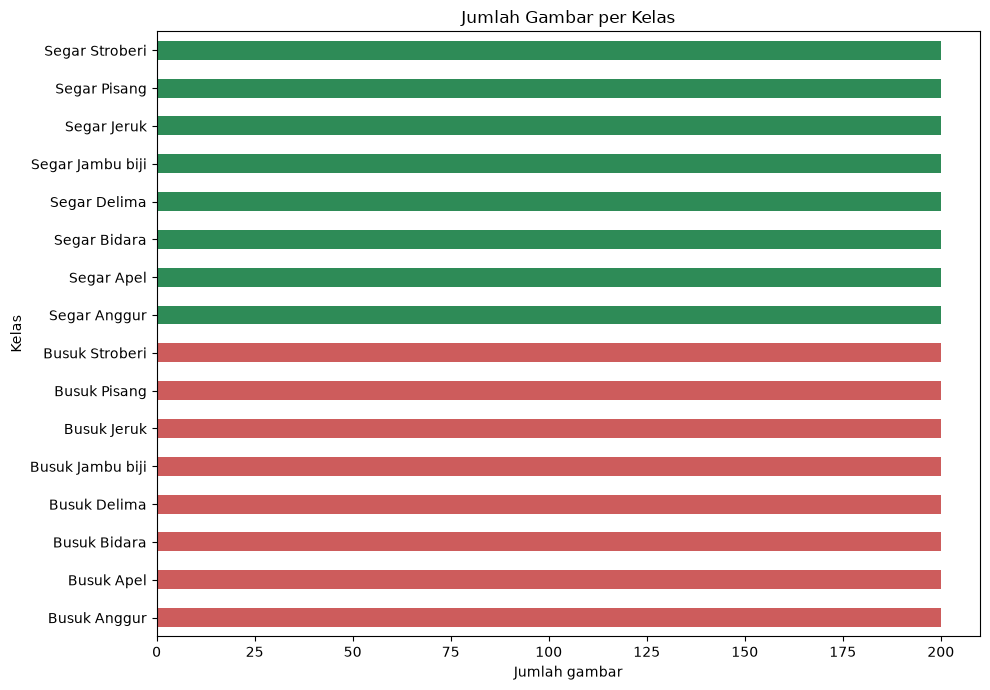

In [3]:
jumlah_per_kelas = (
    data_gambar["kelas"]
    .value_counts()
    .reindex(daftar_kelas, fill_value=0)
    .rename_axis("Kelas")
    .to_frame("Jumlah gambar")
)
display(jumlah_per_kelas)

warna_kelas = [
    "seagreen" if nama_kelas.startswith("Segar") else "indianred"
    for nama_kelas in jumlah_per_kelas.index
]
jumlah_per_kelas["Jumlah gambar"].plot(
    kind="barh", figsize=(10, 7), color=warna_kelas
)
plt.title("Jumlah Gambar per Kelas")
plt.xlabel("Jumlah gambar")
plt.ylabel("Kelas")
plt.tight_layout()
simpan_gambar_jika_belum_ada(plt.gcf(), "jumlah_gambar_per_kelas.png")
plt.show()

## 4. Pemeriksaan resolusi dan format gambar

Periksa metadata seluruh gambar, tampilkan jumlah per format, serta resolusi yang paling sering ditemukan.

In [4]:
metadata_gambar = []
gambar_tidak_valid = []

for baris in data_gambar.itertuples(index=False):
    try:
        with Image.open(baris.lokasi) as gambar:
            metadata_gambar.append(
                {
                    "format": gambar.format,
                    "lebar": gambar.width,
                    "tinggi": gambar.height,
                    "resolusi": f"{gambar.width} x {gambar.height}",
                }
            )
    except (UnidentifiedImageError, OSError) as error:
        gambar_tidak_valid.append({"lokasi": baris.lokasi, "error": str(error)})

if gambar_tidak_valid:
    print(f"Gambar tidak dapat dibaca: {len(gambar_tidak_valid)}")
    display(pd.DataFrame(gambar_tidak_valid))

ringkasan_metadata = pd.DataFrame(metadata_gambar)
if ringkasan_metadata.empty:
    raise ValueError("Tidak ada metadata gambar yang berhasil dibaca.")

print(f"Gambar berhasil diperiksa: {len(ringkasan_metadata):,}")
print(f"Jumlah resolusi unik: {ringkasan_metadata['resolusi'].nunique():,}")
print("Jumlah gambar per format:")
display(
    ringkasan_metadata["format"]
    .value_counts()
    .rename_axis("Format")
    .to_frame("Jumlah gambar")
)
print("10 resolusi yang paling sering ditemukan:")
display(
    ringkasan_metadata["resolusi"]
    .value_counts()
    .head(10)
    .rename_axis("Resolusi (lebar x tinggi)")
    .to_frame("Jumlah gambar")
)
print(
    "Rentang dimensi: "
    f"lebar {ringkasan_metadata['lebar'].min()}-"
    f"{ringkasan_metadata['lebar'].max()} px, "
    f"tinggi {ringkasan_metadata['tinggi'].min()}-"
    f"{ringkasan_metadata['tinggi'].max()} px"
)

Gambar berhasil diperiksa: 3,200
Jumlah resolusi unik: 2,274
Jumlah gambar per format:


,Jumlah gambar
Format,
JPEG,3200


10 resolusi yang paling sering ditemukan:


,Jumlah gambar
Resolusi (lebar x tinggi),
2560 x 1920,223
1920 x 2560,93
1200 x 1600,87
1600 x 1200,50
1040 x 780,18
577 x 433,17
780 x 1040,12
433 x 577,8
2560 x 2242,5


Rentang dimensi: lebar 251-2560 px, tinggi 301-2560 px


## 5. Contoh gambar setiap kelas

Tampilkan satu contoh gambar untuk setiap kombinasi jenis buah dan kondisi.

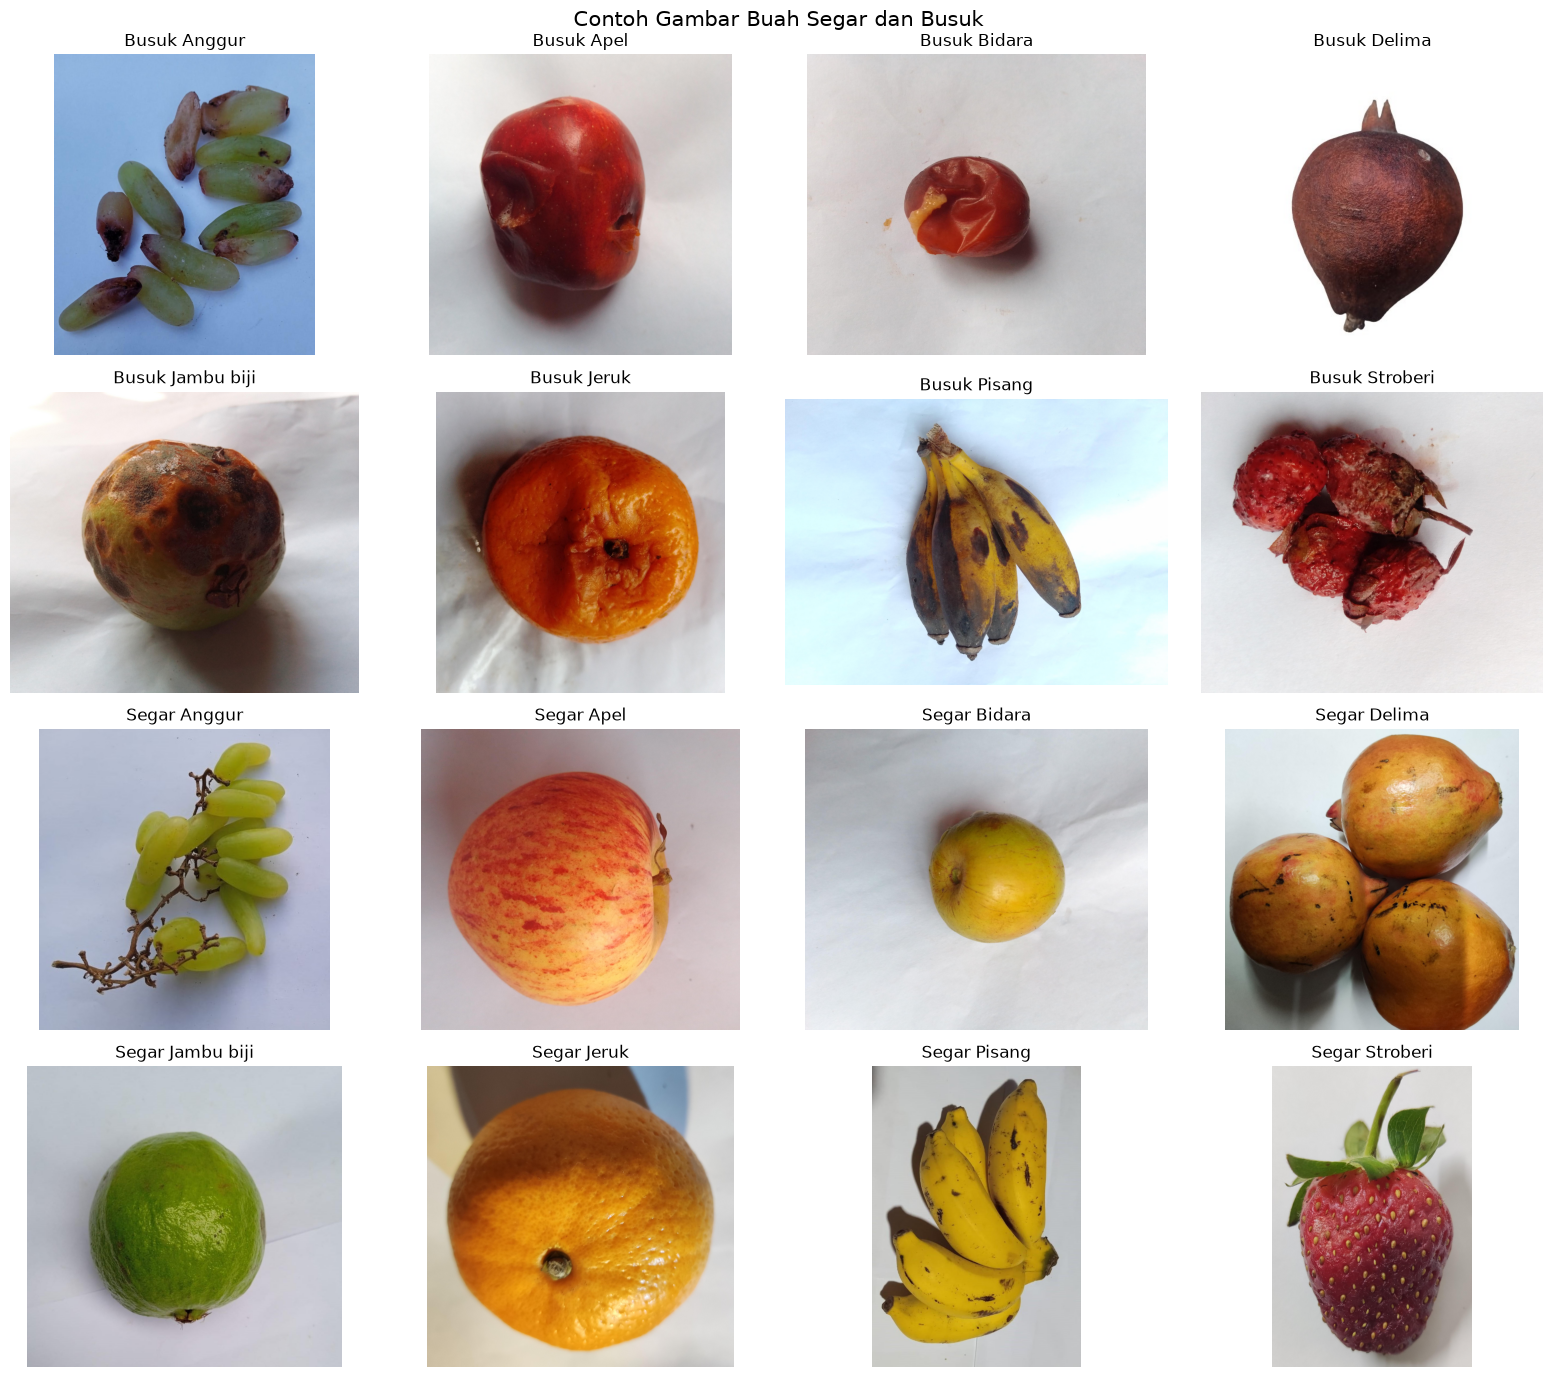

In [5]:
jumlah_contoh = min(
    CONTOH_PER_KELAS,
    int(data_gambar.groupby("kelas").size().min()),
)
contoh_gambar = (
    data_gambar.groupby("kelas", group_keys=False)
    .sample(n=jumlah_contoh, random_state=BENIH_ACAK)
    .reset_index(drop=True)
)

jumlah_kolom = min(4, len(daftar_kelas))
jumlah_baris = math.ceil(len(daftar_kelas) / jumlah_kolom)
fig, axes = plt.subplots(
    jumlah_baris,
    jumlah_kolom,
    figsize=(4 * jumlah_kolom, 3.5 * jumlah_baris),
    squeeze=False,
)

for nomor, nama_kelas in enumerate(daftar_kelas):
    sumbu = axes.flat[nomor]
    pilihan = contoh_gambar[contoh_gambar["kelas"] == nama_kelas].iloc[0]
    with Image.open(pilihan["lokasi"]) as gambar:
        sumbu.imshow(gambar.convert("RGB"))
    sumbu.set_title(nama_kelas)
    sumbu.axis("off")

for sumbu in axes.flat[len(daftar_kelas):]:
    sumbu.axis("off")

fig.suptitle("Contoh Gambar Buah Segar dan Busuk", fontsize=15)
fig.tight_layout()
simpan_gambar_jika_belum_ada(fig, "contoh_gambar_buah.png")
plt.show()

## 6. Praproses data

buang gambar rusak dan duplikat, cek kelas timpang, bagi data jadi train/val/test, cek kebocoran data, lalu simpan ke `split.csv`. File gambar asli tidak dihapus, hanya dikeluarkan dari tabel dan dicatat di `gambar_dibuang.csv`


In [6]:
import hashlib
import json

# Konfigurasi praproses
RASIO_TRAIN = 0.70
RASIO_VAL = 0.15
RASIO_TEST = 0.15
AMBANG_MIRIP = 3          # jarak Hamming dHash maksimum agar dua gambar dianggap hampir sama
SISI_MINIMAL = 32         # gambar dengan sisi lebih kecil dari ini dianggap rusak
RASIO_TIMPANG_MAKS = 1.5  # batas rasio kelas terbesar : terkecil sebelum bobot kelas dipakai

assert abs(RASIO_TRAIN + RASIO_VAL + RASIO_TEST - 1.0) < 1e-9, "Total rasio split harus 1"

indeks_kelas = {nama: nomor for nomor, nama in enumerate(daftar_kelas)}
print(f"Rasio split (train/val/test): {RASIO_TRAIN:.0%} / {RASIO_VAL:.0%} / {RASIO_TEST:.0%}")

Rasio split (train/val/test): 70% / 15% / 15%


### 7. Cek gambar rusak

Setiap gambar dibuka sampai selesai supaya file yang korup atau terpotong ketahuan. Sekalian dihitung MD5 dan dHash untuk dipakai di cek duplikat. Hasilnya: dari 3.200 gambar, tidak ada yang rusak.

In [7]:
def hitung_md5(lokasi):
    hasil = hashlib.md5()
    with open(lokasi, "rb") as berkas:
        for potongan in iter(lambda: berkas.read(1 << 20), b""):
            hasil.update(potongan)
    return hasil.hexdigest()


def hitung_dhash(gambar):
    # dHash 64 bit: bandingkan piksel bertetangga pada versi 9x8 yang digrayscale
    kecil = gambar.convert("L").resize((9, 8), Image.LANCZOS)
    piksel = np.asarray(kecil, dtype=np.int16)
    return (piksel[:, 1:] > piksel[:, :-1]).flatten()


def periksa_gambar(lokasi):
    # Mengembalikan (dhash, None) bila sehat, atau (None, alasan) bila rusak
    try:
        with Image.open(lokasi) as gambar:
            gambar.verify()
        with Image.open(lokasi) as gambar:
            if min(gambar.size) < SISI_MINIMAL:
                return None, "ukuran terlalu kecil"
            gambar.draft("RGB", (256, 256))  # percepat decode JPEG besar
            gambar.load()
            return hitung_dhash(gambar), None
    except (UnidentifiedImageError, OSError, SyntaxError, ValueError) as error:
        return None, f"{type(error).__name__}: {error}"


daftar_md5 = []
daftar_alasan = []
dhash_gambar = {}

for nomor, lokasi in enumerate(data_gambar["lokasi"], start=1):
    dhash, alasan = periksa_gambar(lokasi)
    daftar_alasan.append(alasan)
    if alasan is None:
        dhash_gambar[lokasi] = dhash
        daftar_md5.append(hitung_md5(lokasi))
    else:
        daftar_md5.append(None)
    if nomor % 500 == 0 or nomor == len(data_gambar):
        print(f"Diperiksa: {nomor:,}/{len(data_gambar):,}")

data_periksa = data_gambar.copy()
data_periksa["md5"] = daftar_md5
data_periksa["alasan_rusak"] = daftar_alasan

gambar_rusak = data_periksa[data_periksa["alasan_rusak"].notna()]
print(f"Gambar rusak: {len(gambar_rusak)}")
if len(gambar_rusak) > 0:
    display(gambar_rusak[["lokasi", "kelas", "alasan_rusak"]])

Diperiksa: 500/3,200
Diperiksa: 1,000/3,200
Diperiksa: 1,500/3,200
Diperiksa: 2,000/3,200
Diperiksa: 2,500/3,200
Diperiksa: 3,000/3,200
Diperiksa: 3,200/3,200
Gambar rusak: 0


### 8. Deteksi dan pembuangan duplikat

Duplikat dicek dengan tiga cara: file yang isinya sama persis (MD5), file yang sama tapi beda kelas (semuanya dibuang karena labelnya bertentangan), dan gambar yang hampir sama dalam satu kelas (dHash). Ini dilakukan sebelum split supaya gambar yang sama tidak ada di train dan test sekaligus. Hasilnya, 36 gambar dibuang (7 duplikat persis dan 29 hampir sama), tersisa 3.164 gambar.

In [8]:
def matriks_mirip(tabel):
    # True pada pasangan gambar sekelas dengan jarak Hamming dHash <= AMBANG_MIRIP
    bit = np.stack([dhash_gambar[lokasi] for lokasi in tabel["lokasi"]]).astype(np.float32)
    jarak = bit @ (1 - bit).T
    jarak = jarak + jarak.T
    kelas = tabel["kelas"].to_numpy()
    mirip = (jarak <= AMBANG_MIRIP) & (kelas[:, None] == kelas[None, :])
    np.fill_diagonal(mirip, False)
    return mirip


catatan_dibuang = []

def catat(tabel, alasan):
    for baris in tabel.itertuples(index=False):
        catatan_dibuang.append({"lokasi": baris.lokasi, "kelas": baris.kelas, "alasan": alasan})

# Gambar rusak
catat(gambar_rusak, "gambar rusak")
data_sehat = data_periksa[data_periksa["alasan_rusak"].isna()].copy()

# Duplikat lintas kelas (isi sama, label beda)
kelas_per_md5 = data_sehat.groupby("md5")["kelas"].transform("nunique")
konflik = data_sehat[kelas_per_md5 > 1]
catat(konflik, "duplikat lintas kelas (label bertentangan)")
data_sehat = data_sehat[kelas_per_md5 == 1]

# Duplikat persis (isi sama, kelas sama)
duplikat_persis = data_sehat.duplicated("md5", keep="first")
catat(data_sehat[duplikat_persis], "duplikat persis (MD5 sama)")
data_sehat = data_sehat[~duplikat_persis].reset_index(drop=True)

# Gambar hampir sama (dalam kelas yang sama)
mirip = matriks_mirip(data_sehat)
dibuang_mirip = np.zeros(len(data_sehat), dtype=bool)
for i in range(len(data_sehat)):
    if dibuang_mirip[i]:
        continue
    tetangga = np.where(mirip[i])[0]
    dibuang_mirip[tetangga[tetangga > i]] = True
catat(data_sehat[dibuang_mirip], f"hampir sama (dHash <= {AMBANG_MIRIP})")
data_bersih = data_sehat[~dibuang_mirip].reset_index(drop=True)

log_dibuang = pd.DataFrame(catatan_dibuang, columns=["lokasi", "kelas", "alasan"])

print(f"Jumlah awal         : {len(data_gambar):,}")
print(f"Dibuang             : {len(log_dibuang):,}")
print(f"Jumlah setelah bersih: {len(data_bersih):,}")
if len(log_dibuang) > 0:
    display(
        log_dibuang["alasan"].value_counts().rename_axis("Alasan").to_frame("Jumlah gambar")
    )

Jumlah awal         : 3,200
Dibuang             : 36
Jumlah setelah bersih: 3,164


,Jumlah gambar
Alasan,
hampir sama (dHash <= 3),29
duplikat persis (MD5 sama),7


#### Cek visual gambar hampir sama

Beberapa pasangan yang dibuang ditampilkan untuk memastikan memang foto yang sama (kiri dibuang, kanan dipertahankan). Yang dipertahankan adalah gambar dengan urutan nama file paling awal

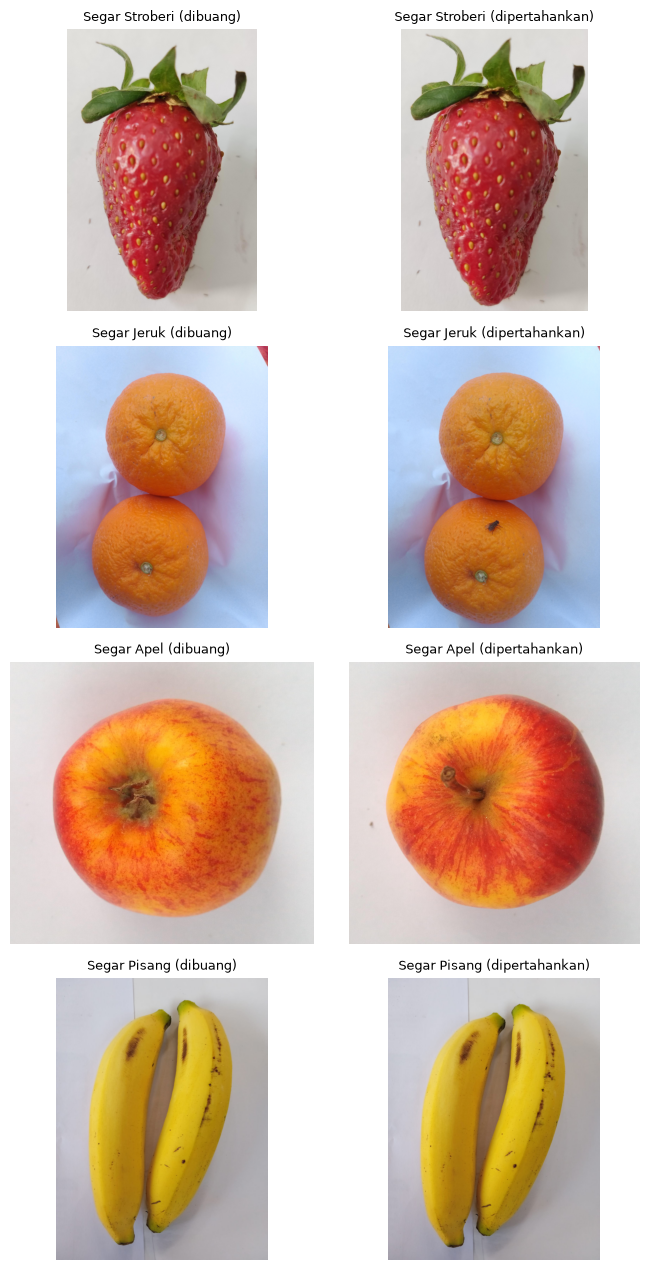

In [9]:
# Cek visual: gambar yang dibuang (kiri) dibandingkan dengan gambar yang dipertahankan (kanan)
indeks_dibuang = np.where(dibuang_mirip)[0]
jumlah_tampil = min(4, len(indeks_dibuang))

if jumlah_tampil == 0:
    print("Tidak ada gambar hampir sama yang dibuang.")
else:
    fig, axes = plt.subplots(jumlah_tampil, 2, figsize=(7, 3.2 * jumlah_tampil), squeeze=False)
    pilihan = np.random.RandomState(BENIH_ACAK).choice(indeks_dibuang, jumlah_tampil, replace=False)
    for baris, j in enumerate(pilihan):
        pasangan = [i for i in np.where(mirip[j])[0] if not dibuang_mirip[i]]
        i = pasangan[0]
        for kolom, (nomor, ket) in enumerate([(j, "dibuang"), (i, "dipertahankan")]):
            with Image.open(data_sehat.loc[nomor, "lokasi"]) as gambar:
                axes[baris, kolom].imshow(gambar.convert("RGB"))
            axes[baris, kolom].set_title(f"{data_sehat.loc[nomor, 'kelas']} ({ket})", fontsize=9)
            axes[baris, kolom].axis("off")
    fig.tight_layout()
    simpan_gambar_jika_belum_ada(fig, "contoh_gambar_hampir_sama_dibuang.png")
    plt.show()

### 9. Penanganan kelas timpang

Jumlah gambar tiap kelas hampir sama, jadi data ini tidak timpang dan tidak perlu oversampling atau undersampling. Oversampling sebelum split juga bisa membuat salinan gambar masuk ke train dan test. Untuk menjaga proporsi kelas, split dibuat per kelas (stratified). Bobot kelas hanya dipakai kalau rasio kelas terbesar dan terkecil lebih dari 1,5.

In [10]:
jumlah_kelas = data_bersih["kelas"].value_counts().reindex(daftar_kelas, fill_value=0)
rasio_timpang = jumlah_kelas.max() / max(jumlah_kelas.min(), 1)

if jumlah_kelas.min() < 10:
    raise ValueError(
        "Ada kelas dengan kurang dari 10 gambar setelah pembersihan: "
        f"{jumlah_kelas.idxmin()} ({jumlah_kelas.min()}). Periksa ulang tahap pembersihan."
    )

pakai_bobot_kelas = bool(rasio_timpang > RASIO_TIMPANG_MAKS)

print(f"Gambar per kelas: min {jumlah_kelas.min()}, maks {jumlah_kelas.max()}")
print(f"Rasio kelas terbesar : terkecil = {rasio_timpang:.2f}")
if pakai_bobot_kelas:
    print("Kelas timpang -> bobot kelas dipakai (dihitung dari data train).")
else:
    print("Kelas relatif seimbang -> tanpa resampling, bobot kelas = 1.")

Gambar per kelas: min 188, maks 200
Rasio kelas terbesar : terkecil = 1.06
Kelas relatif seimbang -> tanpa resampling, bobot kelas = 1.


### 10. Pembagian data train / val / test

Pembagian 70% / 15% / 15% dipilih karena tiap kelas hanya sekitar 200 gambar. Dengan porsi ini train tetap cukup besar (sekitar 140 gambar per kelas), sedangkan val dan test masing-masing sekitar 30 gambar per kelas. Porsi 80/10/10 akan menyisakan hanya sekitar 20 gambar per kelas di val/test, sehingga hasil evaluasinya terlalu berfluktuasi.

Pembagian dilakukan per kelas (stratified) dengan seed `BENIH_ACAK` agar hasilnya bisa diulang.

split,train,val,test
kelas,,,
Busuk Anggur,139,30,30
Busuk Apel,139,30,30
Busuk Bidara,140,30,30
Busuk Delima,136,29,29
Busuk Jambu biji,138,30,30
Busuk Jeruk,139,30,30
Busuk Pisang,140,30,30
Busuk Stroberi,140,30,30
Segar Anggur,139,30,30


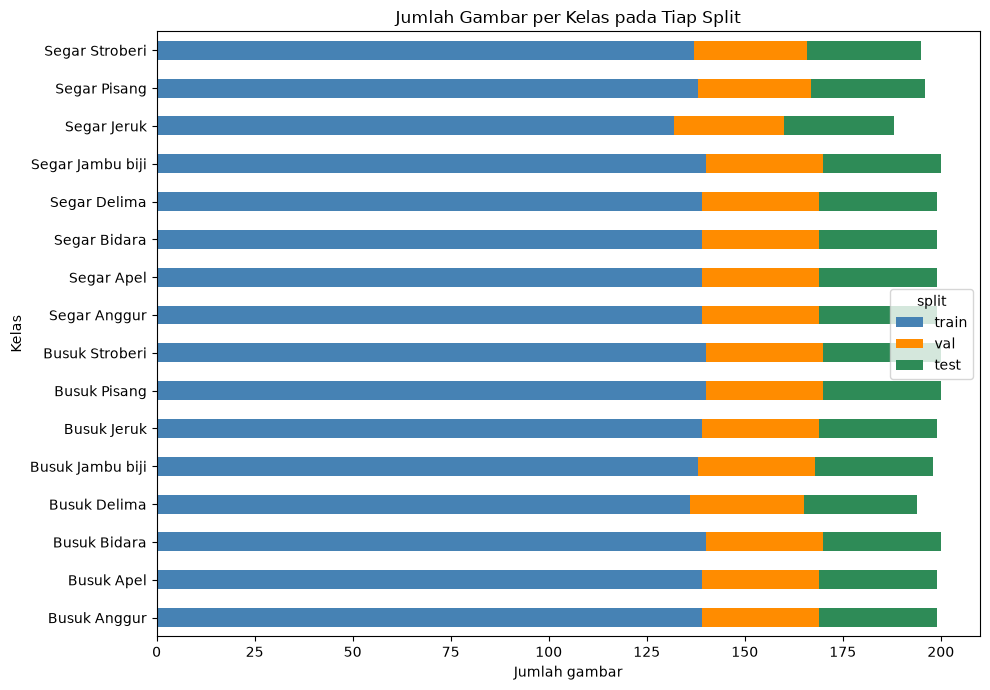

In [11]:
urutan_split = ["train", "val", "test"]
bagian_data = []

for nama_kelas, kelompok in data_bersih.groupby("kelas"):
    kelompok = kelompok.sample(frac=1, random_state=BENIH_ACAK).copy()
    n = len(kelompok)
    n_test = max(1, round(n * RASIO_TEST))
    n_val = max(1, round(n * RASIO_VAL))
    n_train = n - n_val - n_test
    kelompok["split"] = ["test"] * n_test + ["val"] * n_val + ["train"] * n_train
    bagian_data.append(kelompok)

data_split = pd.concat(bagian_data, ignore_index=True)
data_split["label"] = data_split["kelas"].map(indeks_kelas)
data_split["split"] = pd.Categorical(data_split["split"], categories=urutan_split, ordered=True)
data_split = data_split.sort_values(["split", "kelas", "lokasi"], ignore_index=True)
data_split["split"] = data_split["split"].astype(str)

# Bobot kelas: hanya dari data train
jumlah_train = data_split[data_split["split"] == "train"]["kelas"].value_counts()
if pakai_bobot_kelas:
    bobot_kelas = {
        indeks_kelas[k]: float(jumlah_train.sum() / (len(daftar_kelas) * jumlah_train[k]))
        for k in daftar_kelas
    }
else:
    bobot_kelas = {indeks_kelas[k]: 1.0 for k in daftar_kelas}

tabel_split = pd.crosstab(data_split["kelas"], data_split["split"])[urutan_split]
tabel_split.loc["Total"] = tabel_split.sum()
display(tabel_split)

pd.crosstab(data_split["kelas"], data_split["split"])[urutan_split].plot(
    kind="barh", stacked=True, figsize=(10, 7),
    color=["steelblue", "darkorange", "seagreen"],
)
plt.title("Jumlah Gambar per Kelas pada Tiap Split")
plt.xlabel("Jumlah gambar")
plt.ylabel("Kelas")
plt.tight_layout()
simpan_gambar_jika_belum_ada(plt.gcf(), "jumlah_gambar_per_split.png")
plt.show()

### 11.  Pemeriksaan kebocoran data antar split

Empat hal diperiksa: tidak ada file yang sama di dua split, tidak ada isi file (MD5) yang sama di dua split, tidak ada gambar hampir sama (dHash) lintas split dalam kelas yang sama, dan setiap kelas muncul di ketiga split. Jika ada yang gagal, sel ini berhenti dengan pesan error.

In [12]:
pasangan_split = [("train", "val"), ("train", "test"), ("val", "test")]
lokasi_split = {s: set(data_split.loc[data_split["split"] == s, "lokasi"]) for s in urutan_split}
md5_split = {s: set(data_split.loc[data_split["split"] == s, "md5"]) for s in urutan_split}

# 1. Tidak ada file yang sama di dua split
for a, b in pasangan_split:
    irisan = lokasi_split[a] & lokasi_split[b]
    assert not irisan, f"Ada {len(irisan)} file yang sama di {a} dan {b}"

# 2. Tidak ada isi file (MD5) yang sama di dua split
for a, b in pasangan_split:
    irisan = md5_split[a] & md5_split[b]
    assert not irisan, f"Ada {len(irisan)} isi file (MD5) yang sama di {a} dan {b}"

# 3. Tidak ada gambar hampir sama lintas split (dalam kelas yang sama)
mirip_akhir = matriks_mirip(data_split)
label_split = data_split["split"].to_numpy()
lintas_split = mirip_akhir & (label_split[:, None] != label_split[None, :])
assert not lintas_split.any(), f"Ada {int(lintas_split.sum() // 2)} pasangan gambar mirip lintas split"

# 4. Semua kelas ada di ketiga split, dan tidak ada gambar yang hilang atau ganda
assert (tabel_split.drop(index="Total") > 0).all().all(), "Ada kelas yang kosong di salah satu split"
assert data_split["lokasi"].is_unique, "Ada gambar ganda di tabel split"
assert len(data_split) == len(data_bersih), "Jumlah gambar setelah split tidak sama dengan data bersih"

print("Tidak ada kebocoran data antar split.")
print(f"- Jalur file bertabrakan   : 0")
print(f"- Isi file (MD5) sama      : 0")
print(f"- Gambar mirip lintas split: 0")
print(f"- Semua {len(daftar_kelas)} kelas ada di train, val, dan test")

Tidak ada kebocoran data antar split.
- Jalur file bertabrakan   : 0
- Isi file (MD5) sama      : 0
- Gambar mirip lintas split: 0
- Semua 16 kelas ada di train, val, dan test


### 12. Simpan hasil praproses

Kolom `lokasi` di `split.csv` disimpan sebagai jalur relatif terhadap folder proyek, jadi file ini tetap bisa dipakai di komputer anggota lain. Untuk membaca gambar: `FOLDER_PROYEK / lokasi`.

In [13]:
data_simpan = data_split.copy()
data_simpan["lokasi"] = data_simpan["lokasi"].map(
    lambda jalur: Path(jalur).relative_to(FOLDER_PROYEK).as_posix()
)
data_simpan = data_simpan[
    ["lokasi", "kelas_asli", "status", "buah", "kelas", "label", "split", "md5"]
]

lokasi_split_csv = FOLDER_DATA_OLAHAN / "split.csv"
lokasi_log_dibuang = FOLDER_DATA_OLAHAN / "gambar_dibuang.csv"
lokasi_bobot = FOLDER_DATA_OLAHAN / "bobot_kelas.json"

data_simpan.to_csv(lokasi_split_csv, index=False)

log_simpan = log_dibuang.copy()
log_simpan["lokasi"] = log_simpan["lokasi"].map(
    lambda jalur: Path(jalur).relative_to(FOLDER_PROYEK).as_posix()
)
log_simpan.to_csv(lokasi_log_dibuang, index=False)

with open(lokasi_bobot, "w", encoding="utf-8") as berkas:
    json.dump(
        {"indeks_kelas": indeks_kelas, "bobot_kelas": {str(k): v for k, v in bobot_kelas.items()}},
        berkas, ensure_ascii=False, indent=2,
    )

# Baca ulang untuk memastikan file tersimpan dengan benar
cek = pd.read_csv(lokasi_split_csv)
assert len(cek) == len(data_split), "Jumlah baris split.csv tidak sesuai"
assert set(cek["split"]) == set(urutan_split), "Nama split pada split.csv tidak sesuai"
assert all((FOLDER_PROYEK / jalur).is_file() for jalur in cek["lokasi"]), "Ada jalur gambar yang tidak ditemukan"

print(f"split.csv         : {lokasi_split_csv} ({len(cek):,} baris)")
print(f"gambar_dibuang.csv: {lokasi_log_dibuang} ({len(log_simpan):,} baris)")
print(f"bobot_kelas.json  : {lokasi_bobot}")
print("Jumlah gambar per split:")
display(cek["split"].value_counts().reindex(urutan_split).rename_axis("Split").to_frame("Jumlah gambar"))

split.csv         : d:\231111859\latihan python\nyawit_Proyek1\data\processed\split.csv (3,164 baris)
gambar_dibuang.csv: d:\231111859\latihan python\nyawit_Proyek1\data\processed\gambar_dibuang.csv (36 baris)
bobot_kelas.json  : d:\231111859\latihan python\nyawit_Proyek1\data\processed\bobot_kelas.json
Jumlah gambar per split:


,Jumlah gambar
Split,
train,2214
val,475
test,475
